# Variational PINNs: testing the residual instead of collocating it

Strong-form PINNs demand the residual pointwise: $-u''(x_i)-f(x_i)\approx 0$.
For a **point load** $f=\delta(x-a)$ — a concentrated force, heat spike, or
sensor injection — the pointwise residual is *meaningless*: $\delta$ has no
values to collocate. The variational form fixes this the same way finite
elements do — integrate against smooth test functions and move a derivative
off the solution:

$$R_k \;=\; \int_0^1 u'(x)\,v_k'(x)\,dx \;-\; \underbrace{v_k(a)}_{\int \delta(x-a)v_k},
  \qquad v_k(x)=\sin(k\pi x),$$

and minimize $\sum_k R_k^2$ (vPINN; hp-VPINN localizes the test functions
per element). The delta is **exactly representable** under the integral;
the strong form can only smear it into a narrow Gaussian and hope.

Benchmark: $-u'' = \delta(x-a)$ on $[0,1]$, $u(0)=u(1)=0$, $a=\tfrac12$.
Exact solution: the tent function.

The prose describes the **default** run. Change the values below and *Run All*;
every figure and printout follows. Checks that quote slide numbers are skipped
when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0
A_LOAD = 0.5        # position a of the point load
EPS = 0.02          # width of the Gaussian the strong form uses instead of the delta
N_COL = 160         # strong-form collocation points
K = 60              # number of sine test functions (weak form)
WIDTH = 32          # hidden width of both networks
STEPS, LR = 5000, 2e-3
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, A_LOAD=0.5, EPS=0.02, N_COL=160, K=60, WIDTH=32, STEPS=5000, LR=2e-3)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import torch
import matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg, muted
from pyutils.pinn_core import MLP, grad, train
set_plot_style()
torch.set_default_dtype(torch.float64)
torch.manual_seed(SEED); np.random.seed(SEED)

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

## 1. Exact solution, and the strong form's handicap

$-u''=\delta(x-a)$ with $u(0)=u(1)=0$ has the classic tent solution
$u(x)=x(1-a)$ for $x<a$, $a(1-x)$ beyond — the Green's function itself.
A collocation loss needs *values* of $f$, so the strong form must replace
$\delta$ by a narrow Gaussian (a mollified delta) and resolve it with
collocation points — a modeling error before training even starts.

In [3]:
a = A_LOAD
# Green's function of -u'' with homogeneous BCs: the tent function
def u_exact(x):
    x = np.asarray(x)
    return np.where(x < a, x*(1-a), a*(1-x))

# the strong form cannot use a true delta; it gets the standard mollification
eps = EPS
f_np = lambda x: np.exp(-0.5*((np.asarray(x)-a)/eps)**2)/(eps*np.sqrt(2*np.pi))

assert abs(u_exact(1.0)) < 1e-14
print(f"tent solution, peak u({a}) = {u_exact(a):.4f}; strong form uses a "
      f"Gaussian of width eps={eps} as its stand-in for the delta")
print("the mollified problem differs from the true one by O(eps) near the "
      "load -- a modeling error the strong form commits before training")

tent solution, peak u(0.5) = 0.2500; strong form uses a Gaussian of width eps=0.02 as its stand-in for the delta
the mollified problem differs from the true one by O(eps) near the load -- a modeling error the strong form commits before training


## 2. Strong-form PINN on the mollified delta

In [4]:
xc = torch.linspace(0.005, 0.995, N_COL).reshape(-1, 1).requires_grad_(True)
fc = torch.tensor(f_np(xc.detach().numpy()))
xb = torch.tensor([[0.0], [1.0]])

# hard BCs via the cutoff x(1-x): u = x(1-x) N(x) satisfies u(0)=u(1)=0 exactly
net_s = MLP([1, WIDTH, WIDTH, 1])
def u_strong(x):
    return x*(1-x)*net_s(x)

def loss_strong():
    u = u_strong(xc)
    upp = grad(grad(u, xc), xc)
    return ((-upp - fc)**2).mean()

hist_s = train(loss_strong, net_s.parameters(), steps=STEPS, lr=LR)
print(f"strong-form final loss {hist_s[-1]:.3e}")

strong-form final loss 4.060e-04


## 3. vPINN: same network, weak-form loss

Gauss–Legendre quadrature for $\int u'v_k'$; the load term needs no
quadrature at all — $\int \delta(x-a)\,v_k\,dx = v_k(a)$ exactly. Note also
what is differentiated: only **one** derivative of $u$, against the strong
form's two.

In [5]:
# Composite Gauss-Legendre: exact enough for smooth integrands, and the step
# in f is handled by splitting the integral at the jump.
def gauss_nodes(n_sub=64, deg=4):
    gl_x, gl_w = np.polynomial.legendre.leggauss(deg)
    edges = np.linspace(0, 1, n_sub+1)
    xs, ws = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        xs.append(0.5*(hi-lo)*gl_x + 0.5*(hi+lo))
        ws.append(0.5*(hi-lo)*gl_w)
    return np.concatenate(xs), np.concatenate(ws)

xq_np, wq_np = gauss_nodes()
xq = torch.tensor(xq_np.reshape(-1, 1), requires_grad=True)
wq = torch.tensor(wq_np)
Vp = torch.tensor((np.arange(1, K+1)[:, None]*np.pi) *
                  np.cos(np.outer(np.arange(1, K+1), xq_np)*np.pi))       # (K, Nq)
# ∫ delta(x-a) v_k dx = v_k(a): the point load is EXACT under the integral
b_k = torch.tensor(np.sin(np.arange(1, K+1)*np.pi*a))

net_v = MLP([1, WIDTH, WIDTH, 1])
def u_weak(x):
    return x*(1-x)*net_v(x)

def loss_weak():
    u = u_weak(xq)
    up = grad(u, xq).ravel()
    Rk = (Vp * up) @ wq - b_k          # ∫ u' v_k' - ∫ f v_k
    return (Rk**2).mean()

hist_v = train(loss_weak, net_v.parameters(), steps=STEPS, lr=LR)
print(f"weak-form final loss {hist_v[-1]:.3e}")

weak-form final loss 1.161e-04


## 4. Compare

The error plot uses a log axis. Where an error curve crosses or touches zero
the log axis draws a deep notch; those notches carry no meaning.

L_inf error  strong: 7.37e-03   weak: 8.18e-04


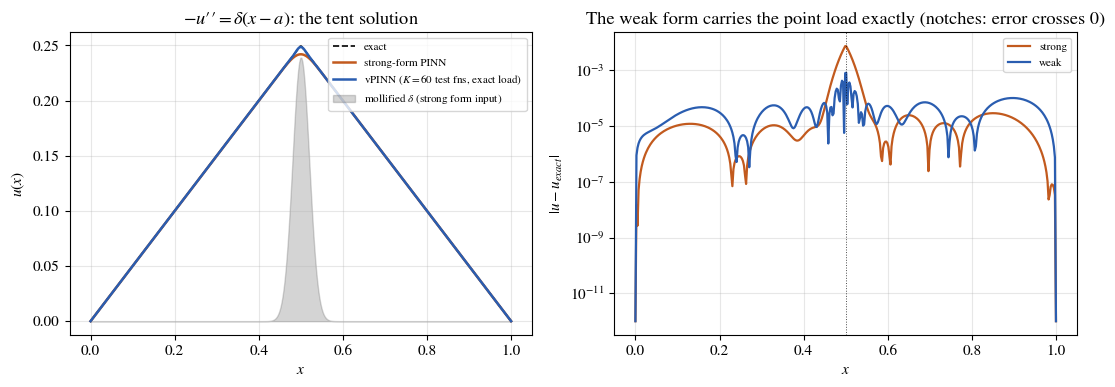

In [6]:
xs = np.linspace(0, 1, 400)
with torch.no_grad():
    xt = torch.tensor(xs.reshape(-1, 1))
    us = (xt*(1-xt)*net_s(xt)).numpy().ravel()
    uv = (xt*(1-xt)*net_v(xt)).numpy().ravel()
ue = u_exact(xs)
es, ev = np.abs(us-ue), np.abs(uv-ue)
print(f"L_inf error  strong: {es.max():.2e}   weak: {ev.max():.2e}")
assert np.isfinite(hist_s).all() and np.isfinite(hist_v).all()
assert ev.max() < es.max()/3, "weak form should clearly beat the mollified strong form"

def plot_vpinn_heat():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(xs, ue, color=fg(), ls='--', lw=1.2, label='exact')
    ax[0].plot(xs, us, color='C1', lw=1.8, label='strong-form PINN')
    ax[0].plot(xs, uv, color='C0', lw=1.8, label=f'vPINN ($K={K}$ test fns, exact load)')
    ax[0].fill_between(xs, 0, 0.012*f_np(xs), color=muted(), alpha=0.25,
                       label='mollified $\\delta$ (strong form input)')
    ax[0].set(xlabel='$x$', ylabel='$u(x)$',
              title='$-u\\prime\\prime = \\delta(x-a)$: the tent solution')
    ax[0].legend(fontsize=8)
    ax[1].semilogy(xs, es+1e-12, color='C1', lw=1.6, label='strong')
    ax[1].semilogy(xs, ev+1e-12, color='C0', lw=1.6, label='weak')
    ax[1].axvline(a, color=fg(), lw=0.7, ls=':', alpha=0.7)
    ax[1].set(xlabel='$x$', ylabel='$|u-u_{exact}|$',
              title='The weak form carries the point load exactly (notches: error crosses 0)')
    ax[1].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_vpinn_heat, 'vpinn_heat', FIG)
plt.show()

## Summary

* The weak form trades pointwise residuals for **tested/integrated**
  residuals — one derivative less on the network, and singular or rough
  loads live under an integral where they are exact, not mollified.
* The sine test functions here are global (vPINN); hp-VPINN uses local test
  functions per element, recovering FEM-style $h$- and $p$-refinement knobs.
* The cost: quadrature bookkeeping, and a choice of test basis — one more
  modeling decision. Weak-form SINDy (module 21) used the same
  integration-by-parts idea to avoid differentiating noisy data.

In [7]:
if AT_DEFAULTS:
    # numbers quoted on the slides and in notes/variants.tex
    assert 6e-3 < es.max() < 9e-3 and 6e-4 < ev.max() < 1.1e-3, (es.max(), ev.max())
    print(f'slide numbers: strong L_inf {es.max():.1e}, weak L_inf {ev.max():.1e}, '
          f'ratio {es.max()/ev.max():.0f}x')
else:
    print('regression check skipped (parameters differ from the slide defaults)')

slide numbers: strong L_inf 7.4e-03, weak L_inf 8.2e-04, ratio 9x
